## Muesli Project ##

**Goal:** check the warehouse manager's and the logistics company's claims against the data and build KPIs for each stage of the order process.

Order received → Ready to ship → On truck → Arrived at customer

In [1]:
# Import pandas to work with DataFrames
# Matplotlib to plot
# Seaborn for simpler plots
# Numpy to work with numerals and NaN
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style='whitegrid')

### 1. Load the data

In [2]:
path = './data/muesli_raw_data.xlsx'
orders = pd.read_excel(path, sheet_name='Orders', header=1)   # the first row of this sheet is empty
process = pd.read_excel(path, sheet_name='Order Process Data')
intern = pd.read_excel(path, sheet_name='InternData Study')
campaign = pd.read_excel(path, sheet_name='Campaign Data')

### 2. Clean column names and remove duplicates

In [3]:
# Same cleaning for every sheet: lowercase and underscores instead of spaces
def clean_columns(df):
    df = df.copy()
    df.columns = df.columns.str.lower().str.replace(' ', '_')
    return df

orders = clean_columns(orders)
process = clean_columns(process).rename(columns={'ship_mode': 'delivery_mode'})  # Express / Standard Processing
intern = clean_columns(intern)
campaign = clean_columns(campaign)

for name, df in [('orders', orders), ('process', process), ('intern', intern), ('campaign', campaign)]:
    print(f'{name:9} rows: {len(df):5}  duplicated rows: {df.duplicated().sum():3}  unique orders: {df.order_id.nunique()}')

orders    rows:  9994  duplicated rows:   0  unique orders: 5009
process   rows:  5899  duplicated rows:   0  unique orders: 3002
intern    rows:   290  duplicated rows:  86  unique orders: 204
campaign  rows:   333  duplicated rows:   0  unique orders: 333


The intern sheet has 86 fully duplicated rows (one row per product, same dates). After `drop_duplicates()` every order appears only once.

In [4]:
intern = intern.drop_duplicates()
print('intern orders unique after dedup:', intern.order_id.is_unique)

intern orders unique after dedup: True


### 3. Data quality checks before merging

- `process.row_id` matches `orders.index` 1:1, and order ID and order date agree for every row, so it is a safe merge key.
- **pickup_date (intern) is always equal to on_truck_scan_date**, so it adds nothing new.
- One order (`CA-2020-101182`) has two different truck scan dates for its two products.

In [5]:
check = process.merge(orders, left_on='row_id', right_on='index', how='left')
print('all process rows found in orders:', check['index'].notna().all())
print('order_id agrees:', (check.order_id_x == check.order_id_y).all())
print('order_date agrees:', (check.order_date_x == check.order_date_y).all())

tmp = process.drop_duplicates('order_id').merge(intern, on='order_id')
print('pickup_date == on_truck_scan_date:', (tmp.pickup_date == tmp.on_truck_scan_date).all())

n_dates = process.groupby('order_id').on_truck_scan_date.nunique()
process[process.order_id.isin(n_dates[n_dates > 1].index)]

all process rows found in orders: True
order_id agrees: True
order_date agrees: True
pickup_date == on_truck_scan_date: True


,row_id,order_id,order_date,on_truck_scan_date,delivery_mode
4216,3080,CA-2020-101182,2020-09-04,2020-09-07,Express
4217,3081,CA-2020-101182,2020-09-04,2020-09-08,Express


### 4. Build one row per order

`process` has **one row per product** (5,899 rows), but the dates belong to the **order** (3,002 orders).
If we calculate stats on product rows, orders with many products count several times
(this is why the old `describe()` showed 418 ready dates although the interns only recorded 204 orders).

So we first `groupby` to one row per order, then left-merge the lookup sheets (see *Merging explanation* doc).

In [6]:
# Add the order details (channel, region, sales ...) at product level first
products = process.merge(
    orders[['index', 'ship_mode', 'origin_channel', 'city', 'state', 'region',
            'category', 'sales', 'quantity', 'profit']],
    left_on='row_id', right_on='index', how='left')

# One row per order
muesli = (products
          .groupby('order_id', as_index=False)
          .agg(order_date=('order_date', 'first'),
               on_truck_scan_date=('on_truck_scan_date', 'max'),  # order is shipped when its last item is on the truck
               delivery_mode=('delivery_mode', 'first'),
               ship_mode=('ship_mode', 'first'),
               origin_channel=('origin_channel', 'first'),
               region=('region', 'first'),
               state=('state', 'first'),
               n_products=('row_id', 'count'),
               sales=('sales', 'sum'),
               quantity=('quantity', 'sum'),
               profit=('profit', 'sum')))

# Left merges: keep all 3,002 orders, sample sheets just fill in where they have data
muesli = muesli.merge(intern[['order_id', 'ready_to_ship_date']], on='order_id', how='left')
muesli = muesli.merge(campaign[['order_id', 'arrival_scan_date']], on='order_id', how='left')

print(muesli.shape)
print('unique orders:', muesli.order_id.nunique())
muesli[['order_date', 'ready_to_ship_date', 'on_truck_scan_date', 'arrival_scan_date']].notna().sum()

(3002, 14)
unique orders: 3002


order_date            3002
ready_to_ship_date     204
on_truck_scan_date    3002
arrival_scan_date      333
dtype: int64

### 5. Stage durations

Every stage is measured in **calendar days** and in **business days** (Mon–Fri), because the warehouse only works on weekdays.

| Stage | From → To | Data available |
|---|---|---|
| Processing | order → ready | intern sample |
| Waiting for truck | ready → truck | intern sample |
| Order to truck | order → truck | **all orders** |
| Transit (3PL) | truck → arrival | campaign sample |
| Total | order → arrival | campaign sample |

In [7]:
def busdays(start, end):
    '''Number of Mon-Fri days between two date columns (NaN if a date is missing).'''
    out = pd.Series(np.nan, index=start.index)
    ok = start.notna() & end.notna()
    out[ok] = np.busday_count(start[ok].values.astype('datetime64[D]'),
                              end[ok].values.astype('datetime64[D]'))
    return out

stages = {
    'processing':     ('order_date', 'ready_to_ship_date'),
    'wait_for_truck': ('ready_to_ship_date', 'on_truck_scan_date'),
    'order_to_truck': ('order_date', 'on_truck_scan_date'),
    'transit':        ('on_truck_scan_date', 'arrival_scan_date'),
    'total':          ('order_date', 'arrival_scan_date'),
}
for stage, (start, end) in stages.items():
    muesli[f'{stage}_days'] = (muesli[end] - muesli[start]).dt.days
    muesli[f'{stage}_bdays'] = busdays(muesli[start], muesli[end])

muesli['order_weekday'] = muesli.order_date.dt.day_name()
muesli.head()

,order_id,order_date,on_truck_scan_date,delivery_mode,ship_mode,origin_channel,region,state,n_products,sales,...,processing_bdays,wait_for_truck_days,wait_for_truck_bdays,order_to_truck_days,order_to_truck_bdays,transit_days,transit_bdays,total_days,total_bdays,order_weekday
0,CA-2019-100041,2019-11-20,2019-11-27,Standard Processing,Standard Class,Sales,Central,Indiana,3,328.540,...,NaN,NaN,NaN,7,5.0,5.0,3.0,12.0,8.0,Wednesday
1,CA-2019-100083,2019-11-24,2019-12-04,Standard Processing,Standard Class,Email,West,Oregon,1,24.784,...,NaN,NaN,NaN,10,7.0,5.0,3.0,15.0,10.0,Sunday
2,CA-2019-100153,2019-12-13,2019-12-18,Standard Processing,Standard Class,Sales,Central,Oklahoma,1,63.880,...,NaN,NaN,NaN,5,3.0,NaN,NaN,NaN,NaN,Friday
3,CA-2019-100202,2019-12-31,2020-01-08,Standard Processing,Standard Class,Email,West,California,1,302.376,...,NaN,NaN,NaN,8,6.0,NaN,NaN,NaN,NaN,Tuesday
4,CA-2019-100244,2019-09-20,2019-09-25,Standard Processing,Standard Class,Sales,West,California,5,475.694,...,2.0,1.0,1.0,5,3.0,5.0,3.0,10.0,6.0,Friday


### 6. Descriptive statistics per stage

In [8]:
day_cols = [f'{s}_days' for s in stages]
summary = muesli[day_cols].describe(percentiles=[.25, .5, .75, .95]).T
summary['cv'] = summary['std'] / summary['mean']   # coefficient of variation = reliability
summary.round(2)

,count,mean,std,min,25%,50%,75%,95%,max,cv
processing_days,204.0,4.18,1.97,0.0,3.0,4.0,6.0,7.0,8.0,0.47
wait_for_truck_days,204.0,1.57,0.95,0.0,1.0,2.0,2.0,3.0,3.0,0.60
order_to_truck_days,3002.0,6.11,2.48,0.0,5.0,7.0,8.0,10.0,12.0,0.41
transit_days,333.0,4.60,1.20,1.0,4.0,5.0,5.0,7.0,7.0,0.26
total_days,333.0,10.83,2.86,3.0,9.0,11.0,13.0,15.0,17.0,0.26


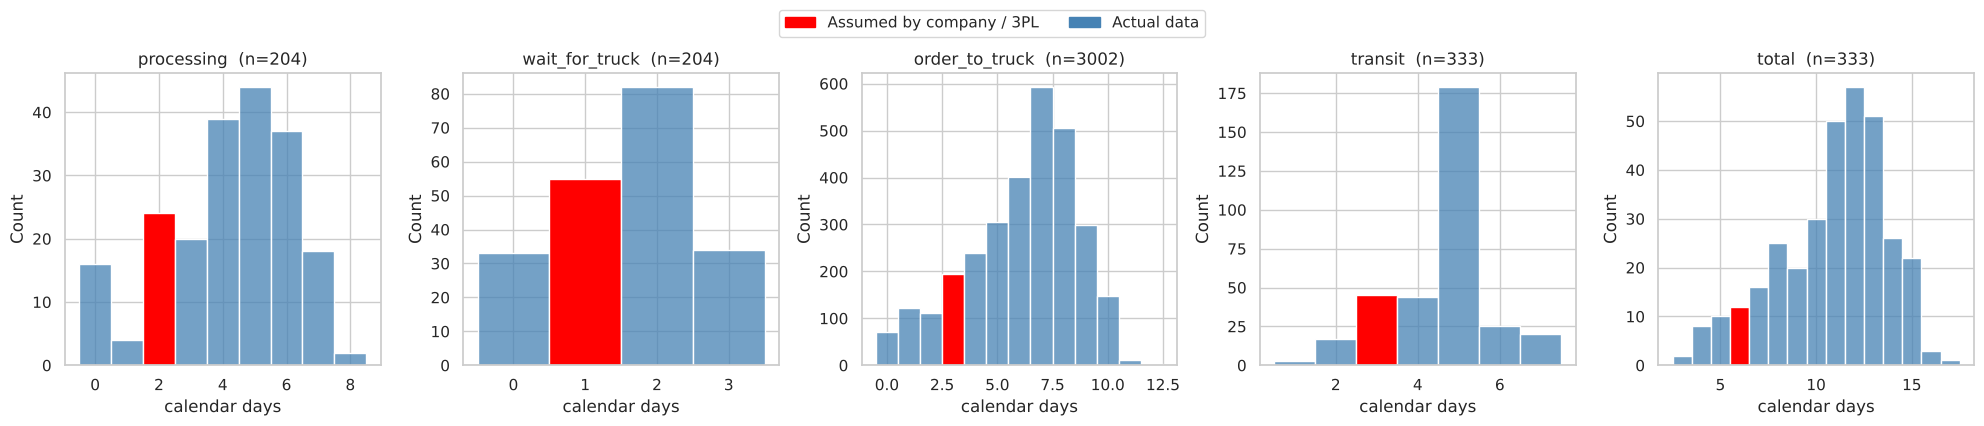

In [9]:
# Value(s) the company/3PL assume for each stage, in calendar days -> these bars are drawn red
assumptions = {
    'processing_days':     [2],     # manager: ~2 days in the warehouse
    'wait_for_truck_days': [1],     # manager: shipped the day after it is ready
    'order_to_truck_days': [3],     # 2 days processing + 1 day to the truck
    'transit_days':        [3],     # 3PL: average 3 days
    'total_days':          [6],     # 3 to the truck + 3 in transit
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, day_cols):
    sns.histplot(muesli[col].dropna(), discrete=True, ax=ax, color='steelblue')

    # discrete=True centres each bar on a whole number, so the centre tells us the day value
    for bar in ax.patches:
        day = round(bar.get_x() + bar.get_width() / 2)
        if day in assumptions[col]:
            bar.set_facecolor('red')

    ax.set_title(f"{col.replace('_days', '')}  (n={muesli[col].notna().sum()})")
    ax.set_xlabel('calendar days')

# One legend for the whole figure
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='red', label='Assumed by company / 3PL'),
                    Patch(color='steelblue', label='Actual data')],
           loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.08))
plt.tight_layout()
plt.show()

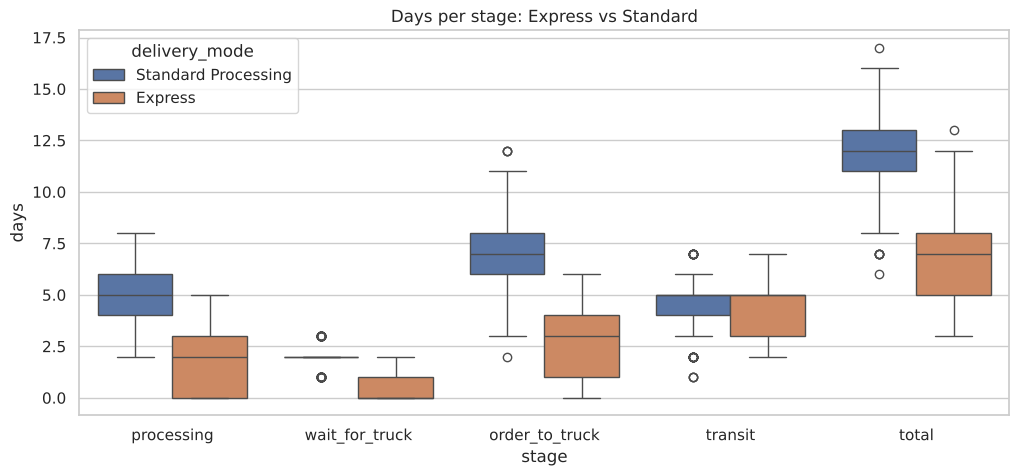

In [10]:
# Boxplots to spot outliers, split by delivery mode
long = muesli.melt(id_vars='delivery_mode', value_vars=day_cols, var_name='stage', value_name='days').dropna()
long['stage'] = long.stage.str.replace('_days', '')
plt.figure(figsize=(12, 5))
sns.boxplot(data=long, x='stage', y='days', hue='delivery_mode')
plt.title('Days per stage: Express vs Standard')
plt.show()

### 7. Check the claims: match or mismatch?

**Warehouse manager**
1. Processing takes 2 (working) days; weekend orders start on Monday.
2. Trucks leave on Mon, Wed and Fri only.
3. Standard orders leave on the next truck after they are ready; Express orders leave on the same day they are ready.

**Logistics company**

4. Average transit time is 3 days.
5. They only deliver on weekdays.

In [11]:
# Claim 1: processing = 2 business days
proc = muesli.processing_bdays.dropna()
print(f'1) Processing: mean {proc.mean():.2f} business days, '
      f'{(proc == 2).mean():.1%} exactly 2, {(proc > 2).mean():.1%} longer, {(proc < 2).mean():.1%} shorter')
print(proc.value_counts().sort_index().to_string(), '\n')

# Claim 2: trucks only on Mon/Wed/Fri
truck_day = muesli.on_truck_scan_date.dt.day_name()
not_truck_day = ~truck_day.isin(['Monday', 'Wednesday', 'Friday'])
print(f'2) Orders put on a truck on Tue/Thu/weekend: {not_truck_day.mean():.1%}')
print(truck_day.value_counts().to_string(), '\n')

1) Processing: mean 2.77 business days, 22.1% exactly 2, 61.3% longer, 16.7% shorter
processing_bdays
0.0    22
1.0    12
2.0    45
3.0    57
4.0    48
5.0    20 

2) Orders put on a truck on Tue/Thu/weekend: 4.1%
on_truck_scan_date
Wednesday    1655
Friday        676
Monday        547
Tuesday        78
Thursday       46 



In [12]:
# Claim 3: the truck rule. Expected truck date given the ready date
TRUCK_DAYS = {0, 2, 4}   # Mon, Wed, Fri

def expected_truck(ready, express):
    '''Express: same day if a truck leaves, Standard: next truck strictly after the ready day.'''
    d = ready if express else ready + pd.Timedelta(days=1)
    while d.weekday() not in TRUCK_DAYS:
        d += pd.Timedelta(days=1)
    return d

has_ready = muesli.ready_to_ship_date.notna()
muesli.loc[has_ready, 'expected_truck'] = muesli[has_ready].apply(
    lambda r: expected_truck(r.ready_to_ship_date, r.delivery_mode == 'Express'), axis=1)
muesli['truck_rule_ok'] = muesli.on_truck_scan_date == muesli.expected_truck

print('3) Truck rule followed (orders with a ready date):')
print(muesli[has_ready].groupby('delivery_mode').truck_rule_ok.agg(['mean', 'count']).round(3))

3) Truck rule followed (orders with a ready date):
                      mean  count
delivery_mode                    
Express              0.943     53
Standard Processing  0.901    151


In [13]:
# Claim 4 and 5: logistics company
transit = muesli.transit_days.dropna()
arrival_day = muesli.arrival_scan_date.dropna().dt.day_name()
print(f'4) Transit: mean {transit.mean():.2f} days (claim: 3), median {transit.median():.0f}, '
      f'{(transit > 3).mean():.1%} take longer than 3 days')
print(f'5) Arrivals on a weekend: {arrival_day.isin(["Saturday", "Sunday"]).mean():.1%}')

4) Transit: mean 4.60 days (claim: 3), median 5, 80.5% take longer than 3 days
5) Arrivals on a weekend: 0.0%


### 8. Full-data check: what *should* order → truck take?

Only **order date** and **truck date** exist for every order, so this is the most reliable KPI.
We simulate the manager's process for each order (weekend orders start Monday → ready after 2 business days → truck rule)
and compare the expected truck date with the real one.

In [14]:
order_d = muesli.order_date.values.astype('datetime64[D]')
muesli['expected_ready'] = pd.to_datetime(np.busday_offset(order_d, 2, roll='forward'))
muesli['expected_truck_full'] = muesli.apply(
    lambda r: expected_truck(r.expected_ready, r.delivery_mode == 'Express'), axis=1)
muesli['truck_delay_days'] = (muesli.on_truck_scan_date - muesli.expected_truck_full).dt.days

print(f'On time or early: {(muesli.truck_delay_days <= 0).mean():.1%}')
print(f'Late:             {(muesli.truck_delay_days > 0).mean():.1%}')
print(muesli.groupby('delivery_mode').truck_delay_days.describe().round(2))

On time or early: 42.9%
Late:             57.1%
                      count  mean   std  min  25%  50%  75%  max
delivery_mode                                                   
Express               662.0 -0.57  1.85 -5.0 -2.0  0.0  0.0  4.0
Standard Processing  2340.0  2.37  2.12 -2.0  0.0  2.0  5.0  7.0


### 9. Is Express worth it?

In [15]:
muesli.groupby('delivery_mode')[day_cols].agg(['mean', 'median', 'count']).round(2).T

delivery_mode               Express  Standard Processing
processing_days     mean       2.04                 4.93
                    median     2.00                 5.00
                    count     53.00               151.00
wait_for_truck_days mean       0.40                 1.99
                    median     0.00                 2.00
                    count     53.00               151.00
order_to_truck_days mean       2.62                 7.09
                    median     3.00                 7.00
                    count    662.00              2340.00
transit_days        mean       4.48                 4.64
                    median     5.00                 5.00
                    count     75.00               258.00
total_days          mean       7.05                11.93
                    median     7.00                12.00
                    count     75.00               258.00

### 10. Does the order weekday matter?

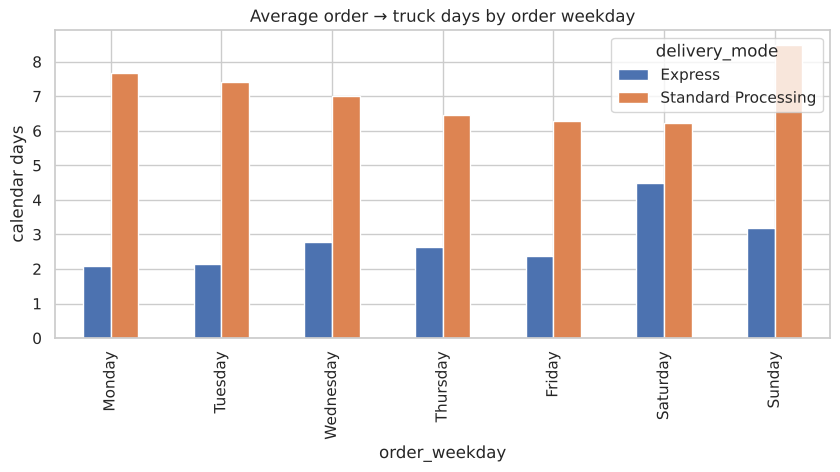

delivery_mode,Express,Standard Processing
order_weekday,,
Monday,2.08,7.67
Tuesday,2.14,7.41
Wednesday,2.78,7.01
Thursday,2.64,6.46
Friday,2.38,6.29
Saturday,4.49,6.23
Sunday,3.17,8.49


In [16]:
week = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = (muesli.groupby(['order_weekday', 'delivery_mode']).order_to_truck_days.mean()
          .unstack().reindex(week))
by_day.plot(kind='bar', figsize=(10, 4), title='Average order → truck days by order weekday')
plt.ylabel('calendar days')
plt.show()
by_day.round(2)

### 11. Channel and region (questions from 'Overall time for delivery')

In [17]:
print(muesli.groupby('origin_channel').order_to_truck_days.agg(['mean', 'median', 'count']).round(2), '\n')
print(muesli.groupby('region').order_to_truck_days.agg(['mean', 'median', 'count']).round(2), '\n')
print(muesli.groupby('region').transit_days.agg(['mean', 'median', 'count']).round(2))

                mean  median  count
origin_channel                     
Email           6.11     7.0   1527
Facebook        6.04     7.0    560
Sales           6.14     7.0    915 

         mean  median  count
region                      
Central  6.14     7.0    711
East     6.14     7.0    844
South    6.06     7.0    487
West     6.07     7.0    960 

         mean  median  count
region                      
Central  4.49     5.0     77
East     4.58     5.0     92
South    4.61     5.0     49
West     4.70     5.0    115


### 12. Key findings (draft for the slides)

| Claim | Data | Verdict |
|---|---|---|
| Processing takes 2 working days | mean 2.8 business days; only 22% exactly 2, 61% longer | **Mismatch** |
| Trucks only Mon/Wed/Fri | 4% of orders were scanned on Tue/Thu | Mostly match |
| Standard: next truck, Express: same day | rule followed for 90% (standard) and 94% (express) | Mostly match |
| Transit averages 3 days | mean 4.6 days, 80% take longer than 3 | **Mismatch** |
| Deliveries only on weekdays | 0% weekend arrivals | Match |

- **Order → truck**, the only KPI with complete data, is late for 57% of orders compared with the manager's process; Standard orders are on average 2.4 days late.
- **Express is worth it:** about 7 days order → arrival vs 12 for Standard. Surprisingly, Express orders are also *processed* faster (2 vs 5 days), not just put on the truck sooner. That's not part of the official process.
- Channel and region make almost no difference (≈6.1 days order → truck everywhere).
- Possible outliers: 22 orders were "ready" on the same day they were ordered (0 days processing).
- Caveat: processing and transit come from small samples (204 and 333 orders), and the intern sample covers only some weeks.